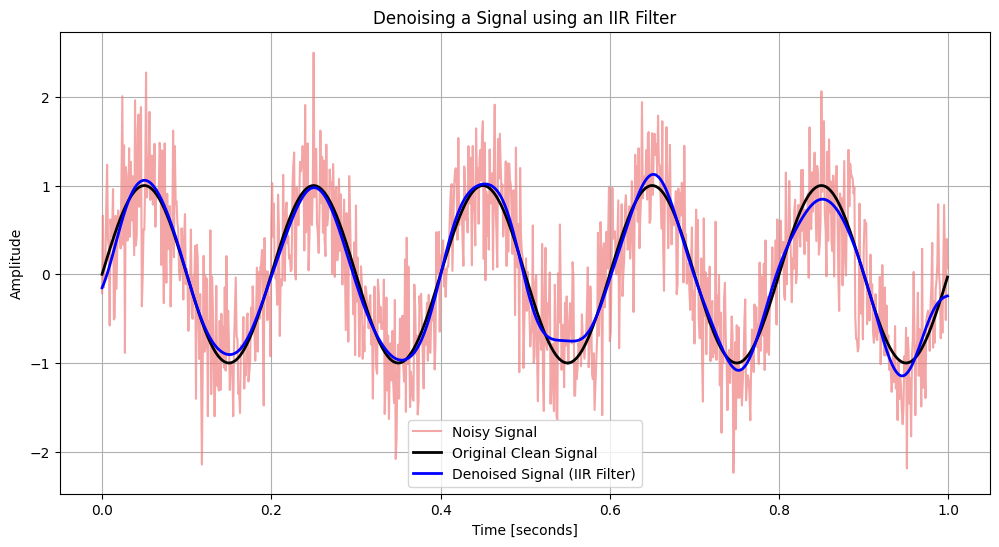

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 1. Generate a clean signal (e.g., a 5 Hz sine wave)
fs = 1000  # Sampling frequency (Hz)
t = np.arange(0, 1.0, 1/fs)  # Time vector (1 second)
clean_signal = np.sin(2 * np.pi * 5 * t)

# 2. Add random Gaussian noise
noise = np.random.normal(0, 0.5, len(t))
noisy_signal = clean_signal + noise

# 3. Design an IIR filter (e.g., a 4th-order Butterworth lowpass filter)
# Cutoff frequency is set to 15 Hz. Normalized cutoff = cutoff / Nyquist
cutoff_hz = 15.0
nyquist = 0.5 * fs
normal_cutoff = cutoff_hz / nyquist
b, a = signal.butter(4, normal_cutoff, btype='low', analog=False)

# 4. Apply the IIR filter using filtfilt for zero-phase distortion
filtered_signal = signal.filtfilt(b, a, noisy_signal)

# 5. Plot the results
plt.figure(figsize=(12, 6))
plt.plot(t, noisy_signal, label='Noisy Signal', color='lightcoral', alpha=0.7)
plt.plot(t, clean_signal, label='Original Clean Signal', color='black', linewidth=2)
plt.plot(t, filtered_signal, label='Denoised Signal (IIR Filter)', color='blue', linewidth=2)
plt.title('Denoising a Signal using an IIR Filter')
plt.xlabel('Time [seconds]')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()